### Evaluación Árboles de decisión y Random Forest destinado a `dia_lluvioso`

**Configuración de atributos y objetivo a evaluar**

In [1]:
X_config = ["hum_carrasco","hum_salto","tmax_carrasco","tmin_carrasco","tmax_salto","tmin_salto",
     "dir_viento_carrasco_prom","int_viento_carrasco_prom",
     "int_racha_viento_carrasco_prom","dir_viento_salto_prom","int_viento_salto_prom",
     "int_racha_viento_salto_prom","vis_carrasco_prom","vis_salto_prom","fen_carrasco_17"]

y_config = ["dia_lluvioso"]


### Caso Árbol de decisión implementación propia
- Emplea datos discretizados
1. **Carga de librerías y módulo propio**  
   Se importa el módulo `algoritmos_clasificacion`

2. **Carga del dataset**  
   ```python
   S = t.cargarDataset("data_dia")
3. **Validación del modelo con CV con 5 splits**<br>
   Arroja un dataframe con los scorings promedios y desviaciones de cada conjunto

In [2]:
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Carga dataset
S = t.cargarDataset("data_dia")

# Configuración atributos y objetivo válidos
X = S[X_config]

y = S[y_config].squeeze() #pasa de df a serie

# #configuración de hiperparámetros a evaluar
criterios = ["gain", "gini", "gain_ratio"]
min_info_gains = [0.003, 0.004, 0.006, 0.008]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion_id3, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, criterios=criterios, hiperparams=min_info_gains)

print("\n Resultados CV")
print(df_validacion_id3.round(4).to_string(index=False))
#tiempo est: 26min




 Resultados CV
  criterio  min_info_gain  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
      gain          0.003         0.7060        0.0044   0.2666  0.0217       0.2418      0.0254          0.2977         0.0155
      gain          0.004         0.7060        0.0044   0.2666  0.0211       0.2418      0.0248          0.2977         0.0151
      gain          0.006         0.7092        0.0041   0.2621  0.0231       0.2340      0.0269          0.2989         0.0156
      gain          0.008         0.7112        0.0049   0.2601  0.0217       0.2299      0.0248          0.3005         0.0161
      gini          0.003         0.7081        0.0048   0.2647  0.0236       0.2379      0.0266          0.2990         0.0184
      gini          0.004         0.7163        0.0053   0.2602  0.0196       0.2257      0.0217          0.3079         0.0162
      gini          0.006         0.7321        0.0085   0.2355  0.0256       0.1873    

**Gráfica de errores según hiperparámetros obtenidos en CV**

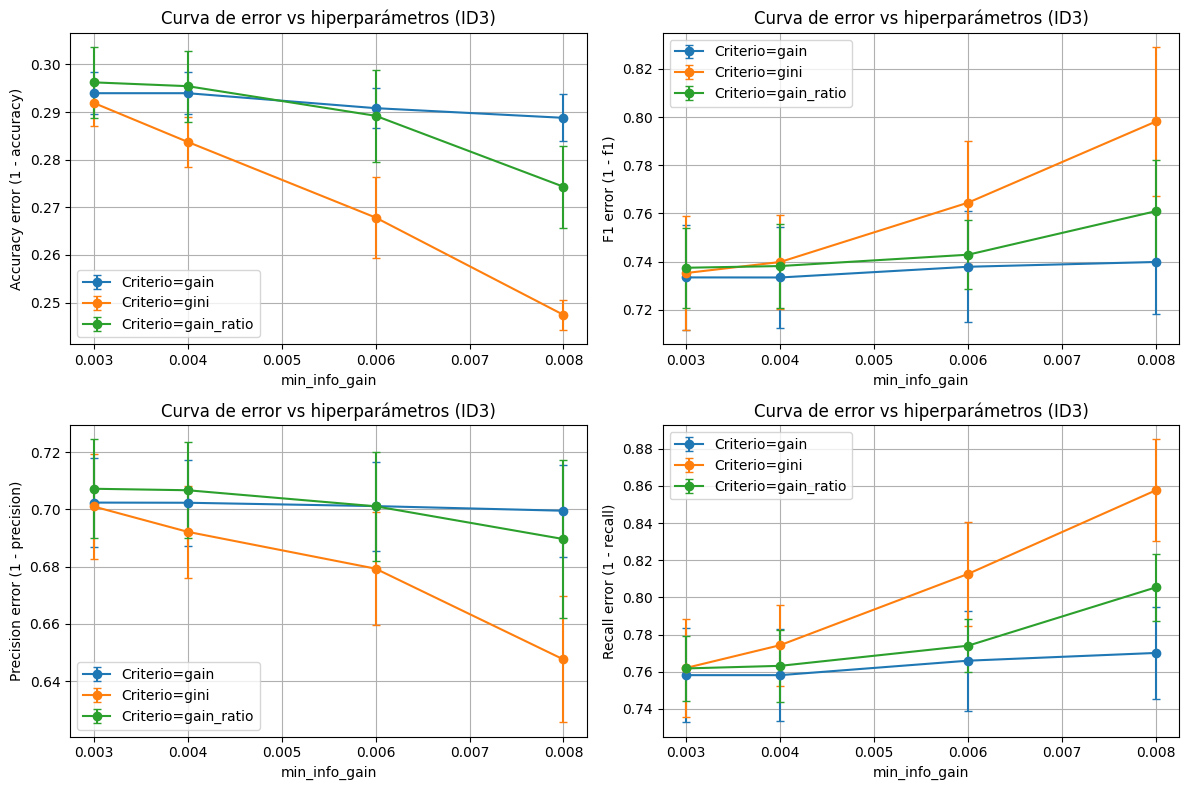

In [3]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

t.funcGraficaError(df_validacion_id3, metric="accuracy", modelo="ID3", ax=axs[0,0])
t.funcGraficaError(df_validacion_id3, metric="f1", modelo="ID3", ax=axs[0,1])
t.funcGraficaError(df_validacion_id3, metric="precision", modelo="ID3", ax=axs[1,0])
t.funcGraficaError(df_validacion_id3, metric="recall", modelo="ID3", ax=axs[1,1])

plt.tight_layout()
plt.show()

#tiempo est: 1seg

1. **Testeo con mejores configuraciones de hiperparámetros obtenidos**  
2. **Obtención de Matrices de Confusión**


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
mejor criterio:  gain mejor min_info_gain:  0.004
Accuracy : 0.7130541871921182
F1       : 0.2677561282212445
Recall   : 0.23666666666666666
Precision: 0.30824891461649784

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
mejor criterio:  gini mejor min_info_gain:  0.008
Accuracy : 0.755911330049261
F1       : 0.18166804293971925
Recall   : 0.12222222222222222
Precision: 0.3536977491961415


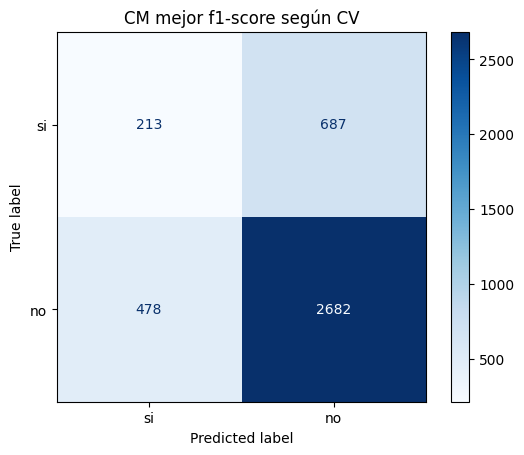

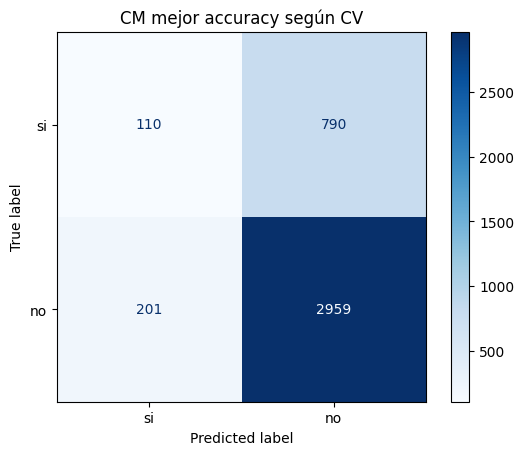

In [4]:
# Evaluación final en test según mejores configuraciones ID3 modificado
y_pred_f = t.testearModelo("ID3", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("ID3", best_cfg_F, y_test, y_pred_f)

y_pred_a = t.testearModelo("ID3", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("ID3", best_cfg_A, y_test, y_pred_a)

# Matrices de confusión
t.graficar_matriz_confusion(y_test, y_pred_f, labels=['si', 'no'], title="CM mejor f1-score según CV")

t.graficar_matriz_confusion(y_test, y_pred_a, labels=['si', 'no'], title="CM mejor accuracy según CV")

#timepo est: 1min

In [5]:
#PRINT ARBOL ID3, descomentar si se prefiere, resulta un arbol muy amplio

# arbol = t.generacion_ID3(S, list(X.columns), "dia_lluvioso", best_cfg_F["min_info_gain"], best_cfg_F["criterio"])
# dot = t.graficar_arbol(arbol)
# dot.render("ARBOL mejor parametrización según f-score", format="png", view=True)

## Caso Random Forest de Sickit Learn
- Emplea datos continuos
1. **Carga de librerías y módulo propio**  
   Se importa el módulo `algoritmos_clasificacion`

2. **Carga del dataset**  
   ```python
   S = t.cargarDataset("data_dia_c")

3. **Validación del modelo con CV con 5 splits**<br>
   Arroja un dataframe con los scorings promedios y desviaciones de cada conjunto

In [6]:
# -------------------------------------------- RANDOM FOREST -------------------------------------------------
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)

# Cargar dataset
S2 = t.cargarDataset("data_dia_c")

# Definir los atributos y objetivo validos
X = S2[X_config]

y = S2[y_config].squeeze() #pasa de df a serie

#configuración de hiperparámetros a evaluar
n_estimators_values = [100, 200, 300, 500]

# Train/Test split (80/20 estratificado)
X_train, X_test, y_train, y_test, = t.split_data(X,y)

# Validación cruzada para selección de hiperparámetros
df_validacion_rf, best_cfg_F, best_cfg_A, best_cfg_P, best_cfg_R = t.validarModelo(X_train, y_train, n_splits=5, hiperparams=n_estimators_values)

print("\n Resultados CV")
print(df_validacion_rf.round(4).to_string(index=False))

#tiempo est: 2 min



 Resultados CV
 n_estimators  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
          100         0.7781        0.0047   0.1478  0.0223       0.0870      0.0141          0.4969         0.0576
          200         0.7788        0.0045   0.1439  0.0133       0.0839      0.0083          0.5104         0.0592
          300         0.7799        0.0037   0.1423  0.0128       0.0825      0.0087          0.5290         0.0567
          500         0.7797        0.0039   0.1395  0.0075       0.0806      0.0050          0.5259         0.0608


**Gráfica de errores según hiperparámetros obtenidos en CV**

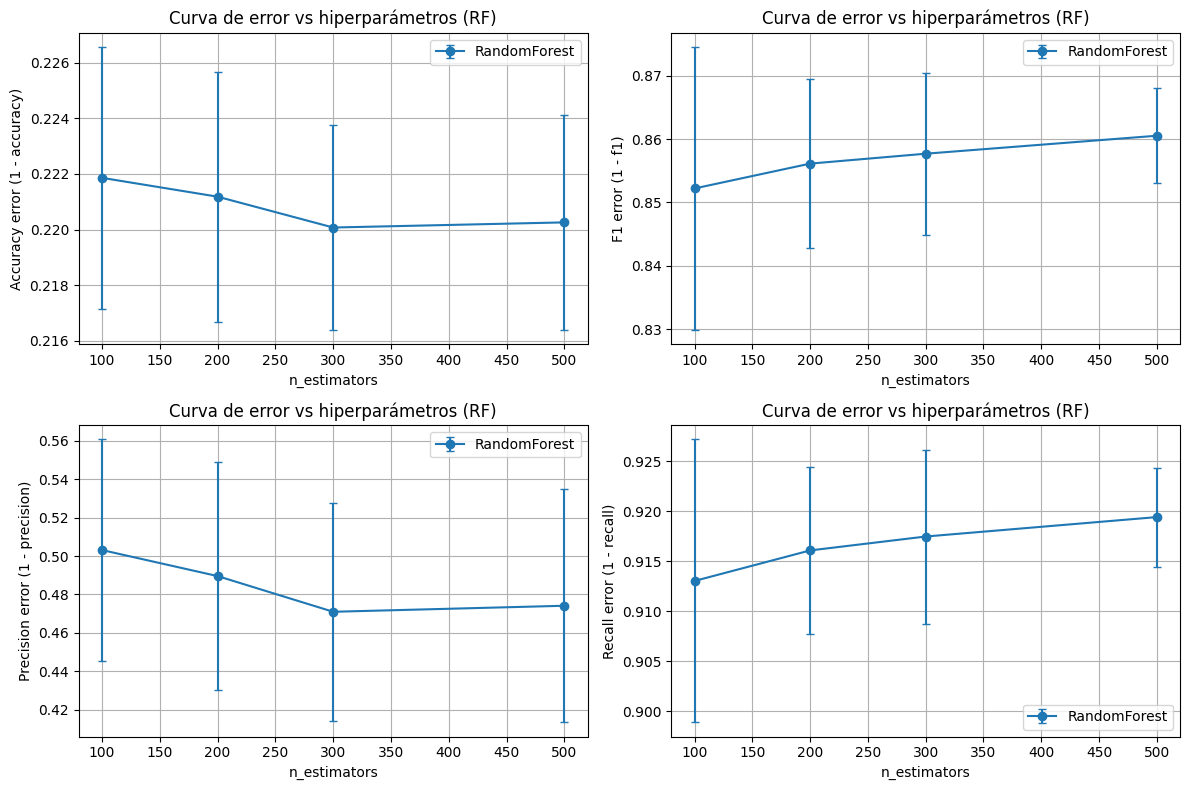

In [7]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2, 2, figsize=(12, 8))

t.funcGraficaError(df_validacion_rf, metric="accuracy", modelo="RF", ax=axs[0,0])
t.funcGraficaError(df_validacion_rf, metric="f1", modelo="RF", ax=axs[0,1])
t.funcGraficaError(df_validacion_rf, metric="precision", modelo="RF", ax=axs[1,0])
t.funcGraficaError(df_validacion_rf, metric="recall", modelo="RF", ax=axs[1,1])

plt.tight_layout()
plt.show()

#tiempo est: 1seg

1. **Testeo con mejores configuraciones de hiperparámetros obtenidos**  
2. **Obtención de Matrices de Confusión**


EVALUACIÓN FINAL EN TEST según mejor criterio por f-score:
nro arboles:  100
Accuracy : 0.774384236453202
F1       : 0.17773788150807898
Recall   : 0.46261682242990654
Precision: 0.11

EVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:
nro arboles:  300
Accuracy : 0.7753694581280788
F1       : 0.1813285457809695
Recall   : 0.11222222222222222
Precision: 0.4719626168224299


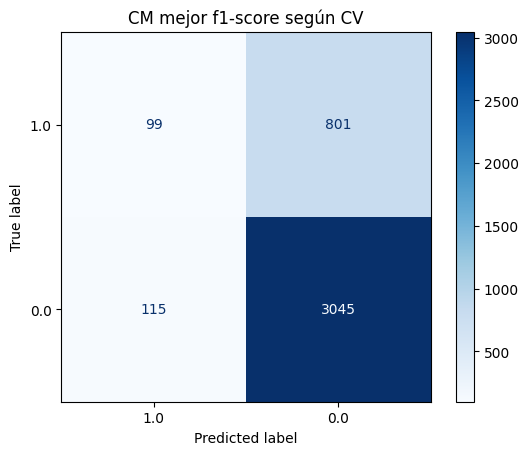

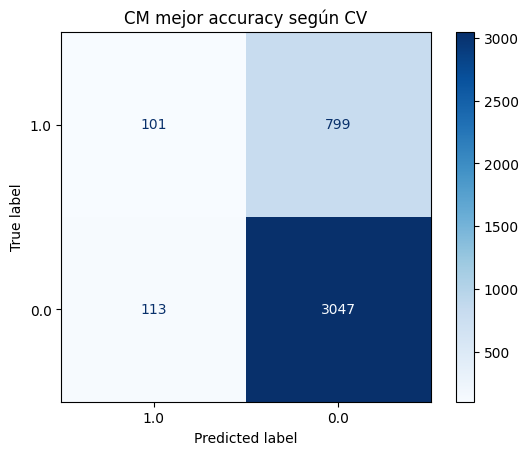

In [8]:
# Evaluación final en test según mejores configuraciones RANDOM FOREST sickit learn
y_pred_f = t.testearModelo("RF", best_cfg_F, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por f-score:")
t.imprimirMetricas("RF", best_cfg_F, y_pred_f, y_test)

y_pred_a = t.testearModelo("RF", best_cfg_A, X_train, y_train, X_test)
print("\nEVALUACIÓN FINAL EN TEST según mejor criterio por accuracy:")
t.imprimirMetricas("RF", best_cfg_A, y_test, y_pred_a)

# Matrices de confusión
t.graficar_matriz_confusion(y_test, y_pred_f, labels=[1.0, 0.0], title="CM mejor f1-score según CV")

t.graficar_matriz_confusion(y_test, y_pred_a, labels=[1.0, 0.0], title="CM mejor accuracy según CV")
#tiempo est: 10seg